# Seminar 6 — Rețele neuronale artificiale în Python
### European Working Conditions Survey (EWCS) 2024

**Statistică aplicată și Data Science** · Master

---

## Întrebarea de cercetare

> **Putem prevedea, pe baza condițiilor de muncă, dacă un salariat are un nivel scăzut de bunăstare psihologică?**

Este o problemă de **clasificare binară**. Lucrăm
pe 22.918 salariați din 35 de țări europene.

## Ce vom face

| # | Secțiune | Timp estimat |
|---|---|---|
| 1 | Datele și dicționarul de variabile | 10 min |
| 2 | Variabila țintă: indicele WHO-5 | 8 min |
| 3 | Explorare rapidă | 7 min |
| 4 | Preprocesare: scalare și one-hot encoding | 10 min |
| 5 | Model de referință: regresie logistică | 5 min |
| 6 | Prima rețea neuronală în Keras | 15 min |
| 7 | Curbele de învățare: epoci și overfitting | 8 min |
| 8 | Evaluarea modelului pe setul de test | 12 min |
| 9 | Hiperparametrii: ce înseamnă și cât contează | 10 min |
| 10 | Ce a învățat rețeaua (permutation importance) | 5 min |
| 11 | Predicții pentru observații noi | 3 min |
| 12 | Concluzii, limite și exerciții | 5 min |

> **Timp de calcul:** rularea întregului notebook durează aproximativ **3–4 minute** pe un
> laptop obișnuit, fără placă grafică. Secțiunea 9 (experimentul pe hiperparametri) ocupă
> cea mai mare parte a acestui timp.


---
## 0. Pregătirea mediului de lucru

Fișierul `ewcs2024_seminar_retele_neuronale.xlsx` trebuie să fie în **același folder**
cu acest notebook.

Dacă bibliotecile nu sunt instalate, rulați o singură dată în terminal (sau
decomentați linia de mai jos):

In [1]:
# !pip install tensorflow pandas numpy scikit-learn matplotlib openpyxl

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.5/223.5 MB 7.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 5.6 MB/s eta 0:00:005.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 4.6 MB/s eta 0:00:004.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.4/565.4 kB 4.5 MB/s eta 0:00:00
Using cached astunparse-1.6.3-py2.py3-none-any.whl (12 kB)
Using cached google_pasta-0.2.0-py3-none-any.whl (57 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 5.7 MB/s eta 0:00:006.1 MB/s eta

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # ascunde mesajele informative ale TensorFlow

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             balanced_accuracy_score, confusion_matrix,
                             classification_report, precision_recall_fscore_support)

import tensorflow as tf
import keras
from keras import layers

# reproductibilitate: fixăm toate generatoarele de numere aleatoare
keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

TensorFlow: 2.21.0 | Keras: 3.15.1


In [3]:
# ---- setări grafice (paletă verde măsliniu, folosită consecvent în tot notebook-ul)
OLIVE, BLUE, TERRA, GREY = "#6F8A1F", "#1565A8", "#B5651D", "#6B6B63"
OLIVE_RAMP = ["#F3F5EA", "#DCE3C4", "#BFCC95", "#9CAD63", "#7A8F3A", "#55651F"]
CMAP_OLIVE = LinearSegmentedColormap.from_list("olive", OLIVE_RAMP)

plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#C9C9C0", "axes.labelcolor": "#2E2E2A",
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.color": "#6B6B63", "ytick.color": "#6B6B63",
    "grid.color": "#E8E8E0", "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 10,
})
pd.set_option("display.max_columns", 50, "display.width", 180)

---
# 1. Datele și dicționarul de variabile

**Sursa:** *European Working Conditions Survey 2024* (Eurofound), colectat prin UK Data Service.

**Eșantionul de lucru:** 22.918 **salariați** activi din 35 de țări europene.
Au fost păstrați doar respondenții care au răspuns la toate întrebările folosite
(persoanele care desfășoară activități independente au fost excluse, pentru că multe
întrebări despre manager sau contract nu li se aplică).

Fișierul Excel are **două foi**:
- `date` — setul de date analitic;
- `dictionar_variabile` — descrierea fiecărei variabile.

In [4]:
XLS = "ewcs2024_seminar_retele_neuronale.xlsx"

df   = pd.read_excel(XLS, sheet_name="date")
dic  = pd.read_excel(XLS, sheet_name="dictionar_variabile")

print(f"Set de date: {df.shape[0]:,} observații × {df.shape[1]} variabile")
print(f"Valori lipsă: {df.isna().sum().sum()}")
df.head(3)

Set de date: 22,918 observații × 32 variabile
Valori lipsă: 0


,uniquerespid,country,calweight,wellbeing,low_wellbeing,age,sex2,isced,seniority,usual_hours,commute_time,monthly_income_eur_imp_ppp,empl_contract,NACE0_lbl,degurba,longday,stress,exhaust_emot,highspeed,wlb_worry,autonomy_methods,support_manager,support_colleagues,fair_treatment,recognition,enough_time,losejob,lonely,discrimination,work_life_balance,make_ends_meet,selfrated_health
0,AL001-007-Z1,Albania,1572.45,76.0,0,30,Feminin,7,0.5,48.0,15,809.69,Fara contract sau altul,Commerce & hospitality,Zona intermediara,0,2,3,7,2,3,4,4,3,4,5,2,2,0,2,4,4
1,AL001-013-Z1,Albania,2562.81,96.0,0,25,Feminin,7,1.0,40.0,20,1643.97,Durata nedeterminata,Health,Zona intermediara,0,2,2,4,3,2,4,5,4,3,5,4,3,0,4,4,5
2,AL001-016-Z1,Albania,1179.34,80.0,0,37,Feminin,7,7.0,40.0,30,4752.39,Durata nedeterminata,Education,Zona intermediara,0,3,2,6,3,4,4,4,4,4,5,1,2,0,4,6,4


## 1.1 Dicționarul de variabile

Înainte de orice modelare, trebuie să știm **ce măsoară** fiecare variabilă, în **ce unitate**
și de **ce tip** este — pentru că tipul variabilei decide cum o preprocesăm
(variabilele numerice se **scalează**, cele categoriale se **codifică one-hot**).

In [5]:
pd.set_option("display.max_colwidth", 70)
dic[["variabila", "label", "unitate_de_masura", "tip_variabila", "scala_valori", "grup"]]

,variabila,label,unitate_de_masura,tip_variabila,scala_valori,grup
0,uniquerespid,ID respondent,–,Identificator (text),cod alfanumeric,Identificare
1,country,Țara,–,Categorială (nominală),35 de țări europene,Context (vezi exercițiul 3)
2,calweight,Ponderea de calibrare,–,Numerică (continuă),> 0,Pondere (vezi exercițiul 4)
3,wellbeing,Scorul WHO-5,puncte (0–100),Numerică (continuă),"0 = minim, 100 = maxim",Sursa variabilei țintă
4,low_wellbeing,Wellbeing scăzut — VARIABILA ȚINTĂ,0/1,Binară (țintă),"0 = wellbeing adecvat, 1 = wellbeing scăzut",VARIABILA ȚINTĂ
5,age,Vârsta,ani,Numerică (continuă),16–88,Socio-demografice
6,sex2,Sexul,–,Categorială (nominală),Masculin / Feminin,Socio-demografice
7,isced,Nivelul de educație (ISCED),nivel (0–8),Numerică (ordinală),0 = preprimar … 8 = doctorat,Socio-demografice
8,seniority,Vechimea în organizație,ani,Numerică (continuă),"0,5–82",Caracteristici ale locului de muncă
9,usual_hours,Ore lucrate pe săptămână,ore/săptămână,Numerică (continuă),> 0,Caracteristici ale locului de muncă


Pentru detalii — semnificația completă și întrebarea originală din chestionarul EWCS:

In [6]:
pd.set_option("display.max_colwidth", 95)
for grup in dic["grup"].unique():
    print(f"\n{'='*100}\n{grup.upper()}\n{'='*100}")
    for _, r in dic[dic["grup"] == grup].iterrows():
        print(f"  {r['variabila']:<28} {r['label']}")
        print(f"  {'':<28} {r['semnificatie']}")
        print(f"  {'':<28} unitate: {r['unitate_de_masura']}  |  tip: {r['tip_variabila']}  |  scală: {r['scala_valori']}")


IDENTIFICARE
  uniquerespid                 ID respondent
                               Identificator unic al respondentului în baza de date EWCS
                               unitate: –  |  tip: Identificator (text)  |  scală: cod alfanumeric

CONTEXT (VEZI EXERCIȚIUL 3)
  country                      Țara
                               Țara în care a fost realizat interviul
                               unitate: –  |  tip: Categorială (nominală)  |  scală: 35 de țări europene

PONDERE (VEZI EXERCIȚIUL 4)
  calweight                    Ponderea de calibrare
                               Ponderea finală de sondaj recomandată de Eurofound pentru estimări reprezentative la nivel european
                               unitate: –  |  tip: Numerică (continuă)  |  scală: > 0

SURSA VARIABILEI ȚINTĂ
  wellbeing                    Scorul WHO-5
                               Indicele WHO-5 de bunăstare psihologică, calculat din cele cinci întrebări who5_* (vesel, relaxat, activ, odihnit, 

### Atenție la direcția scalelor

În chestionarul original EWCS, scalele sunt **inversate**: valoarea `1` înseamnă
*„Întotdeauna"* / *„Acord total"*, iar `5` înseamnă *„Niciodată"* / *„Dezacord total"*.

În setul de date pe care îl folosim, **toate scalele au fost deja re-codificate** astfel
încât **valori mari = mai mult din conceptul măsurat**:

- `stress = 5` → resimte stres **întotdeauna**;
- `support_manager = 5` → managerul îl sprijină **întotdeauna**;
- `selfrated_health = 5` → sănătate **foarte bună**.

Această convenție face interpretarea mult mai simplă.

---
# 2. Variabila țintă: indicele WHO-5

`wellbeing` este **indicele WHO-5 de bunăstare psihologică**, calculat din cinci întrebări
despre cum s-a simțit respondentul în ultimele două săptămâni (vesel, relaxat, activ,
odihnit, interesat de lucruri). Scorul merge de la **0** (minim) la **100** (maxim).

În literatura medicală, pragul de **50 de puncte** este pragul standard de *screening*:
sub 50 se consideră **bunăstare psihologică scăzută**, cu risc crescut de depresie.

Transformăm astfel o variabilă continuă în **ținta binară** de care avem nevoie pentru
clasificare:

$$\text{low\_wellbeing} = \begin{cases} 1 & \text{dacă WHO-5} < 50 \\ 0 & \text{altfel} \end{cases}$$

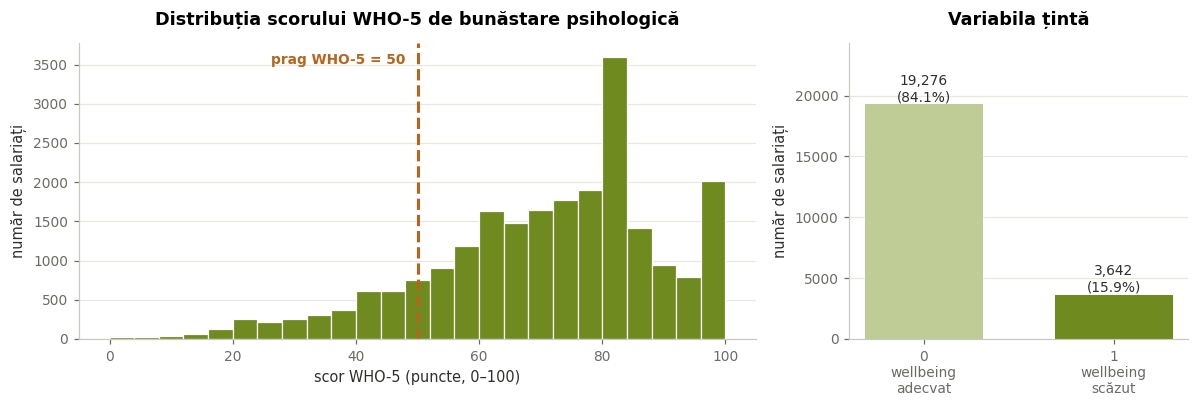

Scor WHO-5 — medie: 69.0 | mediană: 72.0
Rata wellbeing scăzut: 15.9%


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})

# --- distribuția scorului WHO-5, cu pragul de 50
ax1.hist(df["wellbeing"], bins=25, color=OLIVE, edgecolor="white", linewidth=0.8)
ax1.axvline(50, color=TERRA, linewidth=2, linestyle="--")
ax1.text(48, ax1.get_ylim()[1]*0.93, "prag WHO-5 = 50", color=TERRA,
         ha="right", fontsize=9, fontweight="bold")
ax1.set_title("Distribuția scorului WHO-5 de bunăstare psihologică")
ax1.set_xlabel("scor WHO-5 (puncte, 0–100)"); ax1.set_ylabel("număr de salariați")
ax1.grid(axis="y"); ax1.set_axisbelow(True)

# --- distribuția țintei binare
counts = df["low_wellbeing"].value_counts().sort_index()
bars = ax2.bar(["0\nwellbeing\nadecvat", "1\nwellbeing\nscăzut"], counts.values,
               color=[OLIVE_RAMP[2], OLIVE], width=0.62)
for b, v in zip(bars, counts.values):
    ax2.text(b.get_x()+b.get_width()/2, v, f"{v:,}\n({v/len(df)*100:.1f}%)",
             ha="center", va="bottom", fontsize=9, color="#2E2E2A")
ax2.set_title("Variabila țintă")
ax2.set_ylabel("număr de salariați"); ax2.set_ylim(0, counts.max()*1.26)
ax2.grid(axis="y"); ax2.set_axisbelow(True)

plt.tight_layout(); plt.show()

print(f"Scor WHO-5 — medie: {df['wellbeing'].mean():.1f} | mediană: {df['wellbeing'].median():.1f}")
print(f"Rata wellbeing scăzut: {df['low_wellbeing'].mean()*100:.1f}%")

### Interpretare

- Distribuția WHO-5 este **asimetrică la stânga**: majoritatea salariaților raportează un
  nivel bun de bunăstare, iar coada stângă conține cazurile problematice.
- Ținta este **dezechilibrată**: doar aproximativ **16%** din salariați au wellbeing scăzut.

**De ce contează dezechilibrul?** Un model care ar prezice mereu „clasa 0" ar obține o
*accuracy* de 84% fără să învețe absolut nimic. Acesta este motivul pentru care, mai
târziu, vom:
1. folosi **ROC-AUC** și **balanced accuracy** în loc de simpla *accuracy*;
2. transmite rețelei parametrul **`class_weight`**, care penalizează mai puternic
   greșelile pe clasa minoritară.

---
# 3. Explorare rapidă

Înainte de a antrena o rețea, merită să vedem dacă variabilele explicative **chiar
diferă** între cele două grupuri. Dacă nu diferă deloc, nicio rețea nu va putea învăța nimic.

In [8]:
VARS_CHEIE = ["stress", "exhaust_emot", "wlb_worry", "lonely", "losejob",
              "support_manager", "fair_treatment", "recognition", "enough_time",
              "autonomy_methods", "work_life_balance", "make_ends_meet",
              "selfrated_health", "usual_hours", "age"]

cmp = df.groupby("low_wellbeing")[VARS_CHEIE].mean().T
cmp.columns = ["wellbeing adecvat (0)", "wellbeing scăzut (1)"]
cmp["diferență"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp = cmp.join(dic.set_index("variabila")["label"]).sort_values("diferență")
cmp.round(2)[["label", "wellbeing adecvat (0)", "wellbeing scăzut (1)", "diferență"]]

,label,wellbeing adecvat (0),wellbeing scăzut (1),diferență
recognition,Recunoașterea primită,3.82,2.91,-0.91
support_manager,Sprijinul de la manager,3.98,3.34,-0.64
selfrated_health,Starea de sănătate autoevaluată,4.19,3.56,-0.63
fair_treatment,Tratamentul echitabil,4.30,3.70,-0.61
enough_time,Timpul suficient pentru sarcini,4.01,3.43,-0.58
work_life_balance,Echilibrul muncă–viață,3.19,2.73,-0.46
autonomy_methods,Autonomia în metodele de lucru,3.28,3.08,-0.20
losejob,Insecuritatea locului de muncă,1.74,2.08,0.34
lonely,Singurătatea la muncă,1.85,2.32,0.47
make_ends_meet,Dificultatea financiară a gospodăriei,2.83,3.35,0.52


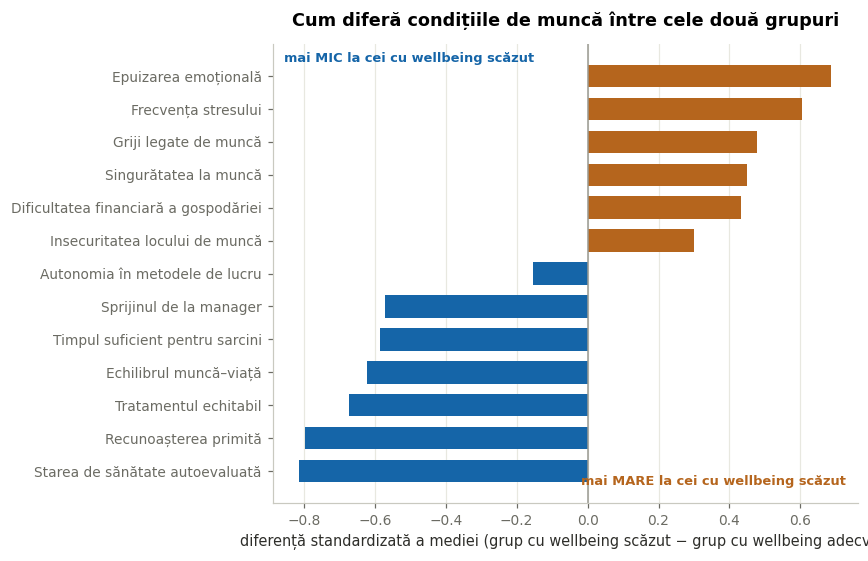

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.2))
d = cmp[cmp.index != "usual_hours"].drop(index="age", errors="ignore")
# diferență standardizată, ca scalele diferite să fie comparabile
dstd = ((df.loc[df.low_wellbeing == 1, d.index].mean()
         - df.loc[df.low_wellbeing == 0, d.index].mean())
        / df[d.index].std()).sort_values()

colors = [BLUE if v < 0 else TERRA for v in dstd.values]
ax.barh(range(len(dstd)), dstd.values, color=colors, height=0.68)
ax.set_yticks(range(len(dstd)))
ax.set_yticklabels([dic.set_index("variabila").loc[i, "label"] for i in dstd.index])
ax.axvline(0, color="#9A9A92", linewidth=1)
ax.set_xlabel("diferență standardizată a mediei (grup cu wellbeing scăzut − grup cu wellbeing adecvat)")
ax.set_title("Cum diferă condițiile de muncă între cele două grupuri")
ax.grid(axis="x"); ax.set_axisbelow(True)
ax.text(0.98, 0.04, "mai MARE la cei cu wellbeing scăzut", transform=ax.transAxes,
        ha="right", color=TERRA, fontsize=8.5, fontweight="bold")
ax.text(0.02, 0.96, "mai MIC la cei cu wellbeing scăzut", transform=ax.transAxes,
        ha="left", color=BLUE, fontsize=8.5, fontweight="bold")
plt.tight_layout(); plt.show()

### Interpretare

Diferențele merg exact în direcția așteptată teoretic (modelul *Job Demands–Resources*):

- **Cerințele muncii** sunt mai ridicate la cei cu wellbeing scăzut: mai mult **stres**,
  mai multă **epuizare emoțională**, mai multe **griji legate de munca în timpul liber**,
  mai multă **singurătate** la locul de muncă.
- **Resursele muncii** sunt mai reduse: mai puțin **sprijin de la manager**, mai puțin
  **tratament echitabil**, mai puțină **recunoaștere**, mai puțin **timp suficient**.
- **Sănătatea autoevaluată** și **echilibrul munca–viață** sunt semnificativ mai slabe,
  iar **dificultatea financiară** mai mare.

Observați că **nicio variabilă nu
este singura decisivă** — tocmai de aceea un model multivariat (rețea neuronală sau
regresie logistică) are sens.

---
# 4. Preprocesare

Trei operații obligatorii înainte de antrenare:

### 4.1 Împărțirea datelor (train / test)
Păstrăm **20%** din observații ca set de **test**, pe care modelul nu îl vede niciodată
în timpul antrenării. Folosim `stratify=y`, ca proporția de 16% să se păstreze în ambele seturi.

### 4.2 Scalarea variabilelor numerice (`StandardScaler`)
**Pasul critic pentru rețelele neuronale.** Variabilele noastre au scale foarte diferite:
venitul e în mii de euro, vârsta în zeci de ani, scalele Likert între 1 și 5.
Rețeaua calculează $z = w_1x_1 + \dots + w_nx_n + b$; dacă $x_1$ este de 1000 de ori mai
mare decât $x_2$, gradienții devin disproporționați și **coborârea pe gradient (gradient
descent) nu converge** sau converge extrem de lent.

`StandardScaler` transformă fiecare variabilă în $z = \dfrac{x - \bar{x}}{s}$ → medie 0,
abatere standard 1.

### 4.3 Codificarea variabilelor categoriale (`OneHotEncoder`)
O rețea neuronală primește doar numere. `sex2`, `empl_contract`, `NACE0_lbl` și `degurba`
devin variabile indicator 0/1 (`drop="first"` elimină o categorie de referință, pentru a
evita coliniaritatea perfectă).

> **Important:** scalarea se „învață" **doar pe setul de antrenare** (`fit_transform`) și se
> **aplică** apoi setului de test (`transform`). Altfel am strecura informație din test în
> antrenare — eroare numită *data leakage*.

In [10]:
CATEGORIALE = ["sex2", "empl_contract", "NACE0_lbl", "degurba"]
EXCLUSE     = ["uniquerespid", "country", "calweight", "wellbeing", "low_wellbeing"]
NUMERICE    = [c for c in df.columns if c not in EXCLUSE + CATEGORIALE]

X = df[NUMERICE + CATEGORIALE]
y = df["low_wellbeing"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

preproc = ColumnTransformer([
    ("num", StandardScaler(), NUMERICE),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORIALE),
])

X_train_p = preproc.fit_transform(X_train)   # fit DOAR pe train
X_test_p  = preproc.transform(X_test)        # doar transform pe test

nume_features = preproc.get_feature_names_out()
N_FEATURES = X_train_p.shape[1]

print(f"Variabile numerice/ordinale : {len(NUMERICE)}")
print(f"Variabile categoriale       : {len(CATEGORIALE)}")
print(f"→ după one-hot encoding     : {N_FEATURES} coloane de intrare (input layer)")
print()
print(f"Set de antrenare : {X_train_p.shape[0]:,} obs. | wellbeing scăzut: {y_train.mean()*100:.1f}%")
print(f"Set de test      : {X_test_p.shape[0]:,} obs. | wellbeing scăzut: {y_test.mean()*100:.1f}%")
print()
print("Verificare scalare (set de antrenare): medie ≈ 0, abatere standard ≈ 1")
print(pd.DataFrame({"medie": X_train_p[:, :len(NUMERICE)].mean(axis=0).round(3),
                    "ab. std": X_train_p[:, :len(NUMERICE)].std(axis=0).round(3)},
                   index=NUMERICE).head(6))

Variabile numerice/ordinale : 23
Variabile categoriale       : 4
→ după one-hot encoding     : 37 coloane de intrare (input layer)

Set de antrenare : 18,334 obs. | wellbeing scăzut: 15.9%
Set de test      : 4,584 obs. | wellbeing scăzut: 15.9%

Verificare scalare (set de antrenare): medie ≈ 0, abatere standard ≈ 1
                            medie  ab. std
age                           0.0      1.0
isced                        -0.0      1.0
seniority                    -0.0      1.0
usual_hours                   0.0      1.0
commute_time                 -0.0      1.0
monthly_income_eur_imp_ppp    0.0      1.0


### Tratarea dezechilibrului de clase

Calculăm ponderi invers proporționale cu frecvența fiecărei clase. Astfel, o greșeală
pe clasa minoritară „costă" mai mult în funcția de cost, iar rețeaua nu mai poate ignora
cei 16% de interes.

In [11]:
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
class_weight = {0: len(y_train) / (2*n0), 1: len(y_train) / (2*n1)}
print("class_weight =", {k: round(v, 3) for k, v in class_weight.items()})
print(f"→ o eroare pe clasa 1 cântărește de {class_weight[1]/class_weight[0]:.1f} ori mai mult")

class_weight = {0: np.float64(0.594), 1: np.float64(3.146)}
→ o eroare pe clasa 1 cântărește de 5.3 ori mai mult


---
# 5. Model de referință: regresia logistică

**Nu antrenăm niciodată o rețea neuronală fără un model de referință (*baseline*).**
Fără un punct de comparație nu putem spune dacă un AUC de 0,82 este bun sau slab.

Regresia logistică este baseline-ul natural: este, de fapt, o rețea neuronală **fără
straturi ascunse** — o singură combinație liniară trecută prin funcția sigmoid. Dacă
rețeaua noastră nu o depășește, înseamnă că relațiile din date sunt în mare parte liniare.

In [12]:
t0 = time.time()
logit = LogisticRegression(max_iter=2000, class_weight="balanced")
logit.fit(X_train_p, y_train)
p_logit = logit.predict_proba(X_test_p)[:, 1]

auc_logit = roc_auc_score(y_test, p_logit)
print(f"REGRESIE LOGISTICĂ  (antrenare: {time.time()-t0:.1f}s)")
print(f"  ROC-AUC           : {auc_logit:.4f}")
print(f"  Accuracy          : {accuracy_score(y_test, p_logit > 0.5):.4f}")
print(f"  Balanced accuracy : {balanced_accuracy_score(y_test, p_logit > 0.5):.4f}")

REGRESIE LOGISTICĂ  (antrenare: 0.1s)
  ROC-AUC           : 0.8220
  Accuracy          : 0.7539
  Balanced accuracy : 0.7434


### Interpretare

**ROC-AUC ≈ 0,82** înseamnă: dacă luăm la întâmplare un salariat cu wellbeing scăzut și
unul cu wellbeing adecvat, modelul atribuie o probabilitate mai mare celui „corect" în
aproximativ 82% din cazuri. Pentru date de sondaj despre un fenomen psihologic complex,
este o performanță bună (0,5 = ghicire pură, 1,0 = clasificare perfectă).

Acesta este valoarea pe care rețeaua neuronală trebuie să o depășească.

---
# 6. Prima rețea neuronală în Keras

Construim o rețea **feedforward** de tip **MLP (Multilayer Perceptron)** — exact
arhitectura din curs. Urmăm cei 6 pași prezentați la Cursul 6.

## Pasul 3: definirea arhitecturii

| Strat | Rol | Neuroni | Activare |
|---|---|---|---|
| **Input layer** | primește variabilele explicative | 37 | — |
| **Hidden layer 1** | învață reprezentări intermediare | 32 | ReLU |
| **Dropout** | regularizare (previne overfitting) | — | — |
| **Hidden layer 2** | combină reprezentările în tipare mai abstracte | 16 | ReLU |
| **Output layer** | produce probabilitatea clasei | 1 | **sigmoid** |

**De ce această arhitectură?**
- **Două straturi ascunse** descrescătoare (32 → 16) sunt o alegere standard pentru date
  tabelare: suficient pentru relații neliniare, fără a risca overfitting pe ~18.000 de observații.
- **ReLU** ($f(z) = \max(0, z)$) în straturile ascunse — introduce neliniaritatea și
  evită problema gradientului care dispare (*vanishing gradient*).
- **Sigmoid** ($\sigma(z) = \frac{1}{1+e^{-z}}$) în stratul de ieșire — comprimă rezultatul
  în intervalul $(0,1)$, deci poate fi citit ca **probabilitate**.

In [13]:
def construieste_model(n_features, straturi=(32, 16), dropout=0.2,
                       learning_rate=1e-3, activare="relu"):
    # Construiește și compilează un MLP pentru clasificare binară.
    model = keras.Sequential(name="MLP_wellbeing")
    model.add(keras.Input(shape=(n_features,)))                      # input layer

    for i, n in enumerate(straturi):                                 # hidden layers
        model.add(layers.Dense(n, activation=activare, name=f"hidden_{i+1}"))
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f"dropout_{i+1}"))

    model.add(layers.Dense(1, activation="sigmoid", name="output"))   # output layer

    # Pasul 4: compilarea — funcția de cost, optimizatorul, metricile
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model


keras.utils.set_random_seed(42)
model = construieste_model(N_FEATURES, straturi=(32, 16), dropout=0.2, learning_rate=1e-3)
model.summary()

Model: "MLP_wellbeing"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,761 (6.88 KB)

 Trainable params: 1,761 (6.88 KB)

 Non-trainable params: 0 (0.00 B)

### De unde vin numerele din `model.summary()`?

Fiecare strat `Dense` are $(\text{intrări} \times \text{neuroni}) + \text{neuroni}$ parametri
— ponderile $w$ plus un **bias** $b$ pentru fiecare neuron:

| Strat | Calcul | Parametri |
|---|---|---|
| `hidden_1` | $37 \times 32 + 32$ | 1.216 |
| `hidden_2` | $32 \times 16 + 16$ | 528 |
| `output` | $16 \times 1 + 1$ | 17 |
| | **Total** | **1.761** |

Straturile `Dropout` nu au parametri — doar dezactivează aleator neuroni în timpul antrenării.

Aceștia sunt **parametrii** pe care rețeaua îi învață din date prin *backpropagation*.
A nu se confunda cu **hiperparametrii** (32, 16, 0.2, 0.001), pe care **noi** îi alegem
înainte de antrenare — și despre care vorbim în secțiunea 9.

## Pasul 5: antrenarea modelului

Trei elemente importante:

- **`validation_split=0.2`** — Keras rezervă 20% din setul de antrenare pentru validare.
  Astfel putem urmări, la fiecare epocă, dacă modelul generalizează sau doar memorează.
  **Setul de test rămâne complet neatins.**
- **`EarlyStopping`** — oprește antrenarea când performanța pe validare nu se mai
  îmbunătățește timp de 10 epoci, și restaurează cele mai bune ponderi. Este modalitatea
  practică de a rezolva dilema din curs: „câte epoci sunt suficiente?".
- **`class_weight`** — ponderile calculate mai sus, pentru dezechilibrul de clase.

In [14]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=10, restore_best_weights=True, verbose=1)

t0 = time.time()
history = model.fit(
    X_train_p, y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=2,            # o linie pe epocă
)
durata = time.time() - t0
print(f"\nAntrenare finalizată în {durata:.1f} secunde, {len(history.history['loss'])} epoci rulate.")

Epoch 1/100
230/230 - 1s - 4ms/step - accuracy: 0.6744 - auc: 0.7374 - loss: 0.6018 - val_accuracy: 0.6899 - val_auc: 0.7971 - val_loss: 0.5695
Epoch 2/100
230/230 - 0s - 637us/step - accuracy: 0.7162 - auc: 0.7952 - loss: 0.5511 - val_accuracy: 0.7047 - val_auc: 0.8090 - val_loss: 0.5528
Epoch 3/100
230/230 - 0s - 698us/step - accuracy: 0.7222 - auc: 0.8043 - loss: 0.5410 - val_accuracy: 0.7197 - val_auc: 0.8138 - val_loss: 0.5298
Epoch 4/100
230/230 - 0s - 615us/step - accuracy: 0.7304 - auc: 0.8088 - loss: 0.5357 - val_accuracy: 0.7278 - val_auc: 0.8155 - val_loss: 0.5296
Epoch 5/100
230/230 - 0s - 616us/step - accuracy: 0.7349 - auc: 0.8138 - loss: 0.5289 - val_accuracy: 0.7199 - val_auc: 0.8172 - val_loss: 0.5305
Epoch 6/100
230/230 - 0s - 627us/step - accuracy: 0.7367 - auc: 0.8186 - loss: 0.5253 - val_accuracy: 0.7287 - val_auc: 0.8178 - val_loss: 0.5246
Epoch 7/100
230/230 - 0s - 673us/step - accuracy: 0.7366 - auc: 0.8182 - loss: 0.5230 - val_accuracy: 0.7273 - val_auc: 0.8190

230/230 - 2s - 8ms/step - accuracy: 0.6744 - auc: 0.7374 - loss: 0.6018 - val_accuracy: 0.6899 - val_auc: 0.7971 - val_loss: 0.5695


Epoch 2/100


230/230 - 1s - 3ms/step - accuracy: 0.7162 - auc: 0.7952 - loss: 0.5511 - val_accuracy: 0.7047 - val_auc: 0.8090 - val_loss: 0.5528


Epoch 3/100


230/230 - 1s - 3ms/step - accuracy: 0.7226 - auc: 0.8044 - loss: 0.5409 - val_accuracy: 0.7202 - val_auc: 0.8139 - val_loss: 0.5293


... (49 outputs left out)

230/230 - 1s - 3ms/step - accuracy: 0.7513 - auc: 0.8381 - loss: 0.4975 - val_accuracy: 0.7374 - val_auc: 0.8196 - val_loss: 0.5128


Epoch 28: early stopping


Restoring model weights from the end of the best epoch: 18.



Antrenare finalizată în 23.2 secunde, 28 epoci rulate.


### Interpretare

Urmăriți cele patru coloane din fiecare linie:

- **`loss`** (binary cross-entropy pe antrenare) — scade constant: rețeaua învață.
- **`val_loss`** — scade la început, apoi se **plafonează** și începe să **crească**.
  Momentul în care `val_loss` urcă în timp ce `loss` continuă să scadă este
  **exact definiția overfitting-ului** din curs.
- **`auc` vs. `val_auc`** — diferența dintre ele arată cât de mult modelul s-a „lipit" de
  datele de antrenare.

`EarlyStopping` a oprit antrenarea și a restaurat ponderile de la epoca cu cel mai bun
`val_auc` — nu de la ultima epocă.

## Verificare: refacem „de mână" calculul din curs

La Cursul 6 am calculat manual, pentru exemplul cu e-mailuri, suma ponderată a unui
neuron și apoi activarea. Acum facem exact același lucru, dar cu **ponderile reale
învățate de rețeaua noastră**, pe o singură observație din setul de test:

$$z^{(l)} = W^{(l)}a^{(l-1)} + b^{(l)}, \qquad a^{(l)} = f(z^{(l)})$$

In [15]:
x0 = X_test_p[0:1]                                      # o singură observație (1 × 37)

W1, b1 = model.get_layer("hidden_1").get_weights()      # ponderile și bias-urile
W2, b2 = model.get_layer("hidden_2").get_weights()
W3, b3 = model.get_layer("output").get_weights()

# --- propagarea înainte (forward propagation), strat cu strat
z1 = x0 @ W1 + b1;          a1 = np.maximum(0, z1)      # hidden 1 + ReLU
z2 = a1 @ W2 + b2;          a2 = np.maximum(0, z2)      # hidden 2 + ReLU
z3 = a2 @ W3 + b3                                       # output: suma ponderată
y_hat = 1 / (1 + np.exp(-z3))                           # funcția sigmoid

print(f"Primul neuron ascuns : z = {z1[0,0]:+.4f}  →  ReLU(z) = {a1[0,0]:.4f}")
print(f"Al doilea neuron     : z = {z1[0,1]:+.4f}  →  ReLU(z) = {a1[0,1]:.4f}")
print(f"Stratul de ieșire    : z = {z3[0,0]:+.4f}  →  sigmoid(z) = {y_hat[0,0]:.4f}")
print()
print(f"Neuroni activi (ReLU > 0): {(a1 > 0).sum()} din {a1.shape[1]} în hidden_1, "
      f"{(a2 > 0).sum()} din {a2.shape[1]} în hidden_2")
print()
print(f"Calcul manual   : {y_hat[0,0]:.6f}")
print(f"model.predict() : {model.predict(x0, verbose=0)[0,0]:.6f}   ← identice")

Primul neuron ascuns : z = -1.1336  →  ReLU(z) = 0.0000
Al doilea neuron     : z = -1.1853  →  ReLU(z) = 0.0000
Stratul de ieșire    : z = +0.4054  →  sigmoid(z) = 0.6000

Neuroni activi (ReLU > 0): 14 din 32 în hidden_1, 6 din 16 în hidden_2

Calcul manual   : 0.599974
model.predict() : 0.599974   ← identice


### Interpretare

Observați **efectul funcției ReLU**: neuronii pentru care $z < 0$ produc exact `0` —
sunt „stinși" pentru această observație. Fiecare observație activează o **submulțime
diferită** de neuroni, iar aceasta este, în esență, sursa neliniarității rețelei.

Rezultatul final coincide cu ce returnează `model.predict()`: o rețea neuronală nu este
o cutie magică, ci un lanț de înmulțiri de matrici și funcții de activare.

---
# 7. Curbele de învățare

Cel mai util grafic din tot procesul de antrenare: arată simultan **dacă rețeaua învață**
și **când începe să memoreze**.

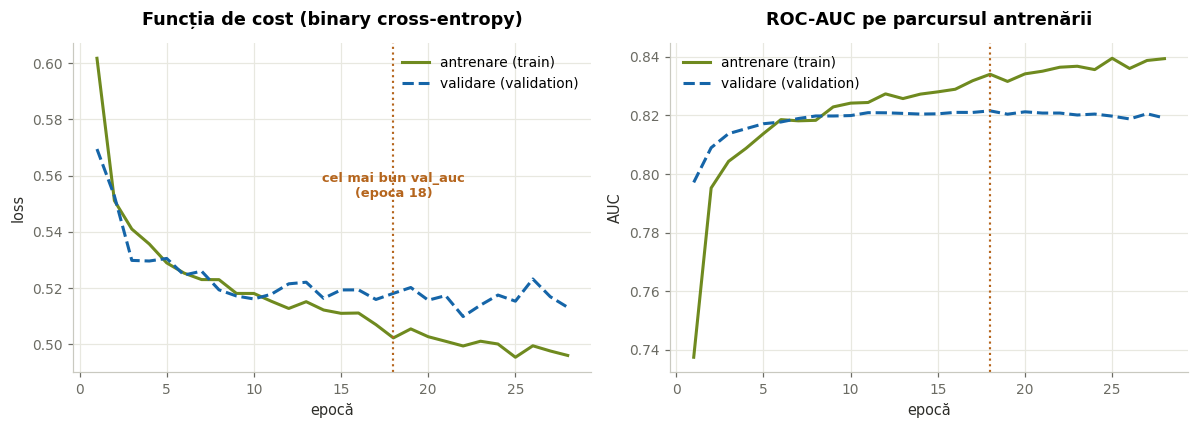

Cea mai bună epocă (val_auc): 18  →  val_auc = 0.8216
Ultima epocă rulată         : 28
Decalaj train−validation la final: AUC +0.0203


In [15]:
h = history.history
epoci = range(1, len(h["loss"]) + 1)
best = int(np.argmax(h["val_auc"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (k_tr, k_val, titlu, ylab) in zip(axes, [
        ("loss", "val_loss", "Funcția de cost (binary cross-entropy)", "loss"),
        ("auc",  "val_auc",  "ROC-AUC pe parcursul antrenării", "AUC")]):
    ax.plot(epoci, h[k_tr],  color=OLIVE, linewidth=2, label="antrenare (train)")
    ax.plot(epoci, h[k_val], color=BLUE,  linewidth=2, linestyle="--", label="validare (validation)")
    ax.axvline(best, color=TERRA, linewidth=1.4, linestyle=":")
    ax.set_title(titlu); ax.set_xlabel("epocă"); ax.set_ylabel(ylab)
    ax.grid(True); ax.set_axisbelow(True); ax.legend(loc="best")

axes[0].annotate(f"cel mai bun val_auc\n(epoca {best})", xy=(best, max(h["val_loss"])*0.97),
                 fontsize=8.5, color=TERRA, ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Cea mai bună epocă (val_auc): {best}  →  val_auc = {h['val_auc'][best-1]:.4f}")
print(f"Ultima epocă rulată         : {len(h['loss'])}")
print(f"Decalaj train−validation la final: AUC {h['auc'][-1]-h['val_auc'][-1]:+.4f}")

### Interpretare — cum se citesc curbele de învățare

| Ce vedem | Diagnostic | Ce facem |
|---|---|---|
| Ambele curbe scad și converg | antrenare corectă | nimic |
| `val_loss` **crește**, `loss` scade | **overfitting** | mai puține epoci, mai mult dropout, rețea mai mică |
| Ambele curbe rămân sus / platou înalt | **underfitting** | mai mulți neuroni/straturi, learning rate mai mare, mai multe epoci |
| Curbe foarte „zimțate" | learning rate prea mare sau batch prea mic | reduceți learning rate, creșteți batch size |

În cazul nostru, cele două curbe rămân apropiate, iar decalajul train–validation este mic.
Rețeaua **nu suferă de overfitting sever**, în bună parte datorită combinației
*dropout 0,2 + EarlyStopping* și a dimensiunii reduse a modelului (1.761 parametri
pentru ~18.000 de observații).

---
# 8. Evaluarea pe setul de test

Abia acum folosim setul de test — o singură dată, pentru verdictul final.

In [16]:
p_nn    = model.predict(X_test_p, verbose=0).ravel()   # probabilități
pred_nn = (p_nn > 0.5).astype(int)                     # decizii, la pragul 0,5
auc_nn  = roc_auc_score(y_test, p_nn)

pred_logit = (p_logit > 0.5).astype(int)
comparatie = pd.DataFrame({
    "Rețea neuronală": [auc_nn,
                        accuracy_score(y_test, pred_nn),
                        balanced_accuracy_score(y_test, pred_nn)],
    "Regresie logistică": [auc_logit,
                           accuracy_score(y_test, pred_logit),
                           balanced_accuracy_score(y_test, pred_logit)],
}, index=["ROC-AUC", "Accuracy", "Balanced accuracy"])

print(comparatie.round(4).to_string())
print(f"\nReper: un model care ar prezice mereu clasa 0 ar avea "
      f"accuracy = {1 - y_test.mean():.4f} și balanced accuracy = 0,5000")
print("\nRaport detaliat — rețeaua neuronală:\n")
print(classification_report(y_test, pred_nn, digits=3,
                            target_names=["wellbeing adecvat (0)", "wellbeing scăzut (1)"]))

                   Rețea neuronală  Regresie logistică
ROC-AUC                     0.8191              0.8220
Accuracy                    0.7369              0.7539
Balanced accuracy           0.7489              0.7434

Reper: un model care ar prezice mereu clasa 0 ar avea accuracy = 0.8412 și balanced accuracy = 0,5000

Raport detaliat — rețeaua neuronală:

                       precision    recall  f1-score   support

wellbeing adecvat (0)      0.943     0.731     0.824      3856
 wellbeing scăzut (1)      0.350     0.766     0.481       728

             accuracy                          0.737      4584
            macro avg      0.647     0.749     0.652      4584
         weighted avg      0.849     0.737     0.769      4584



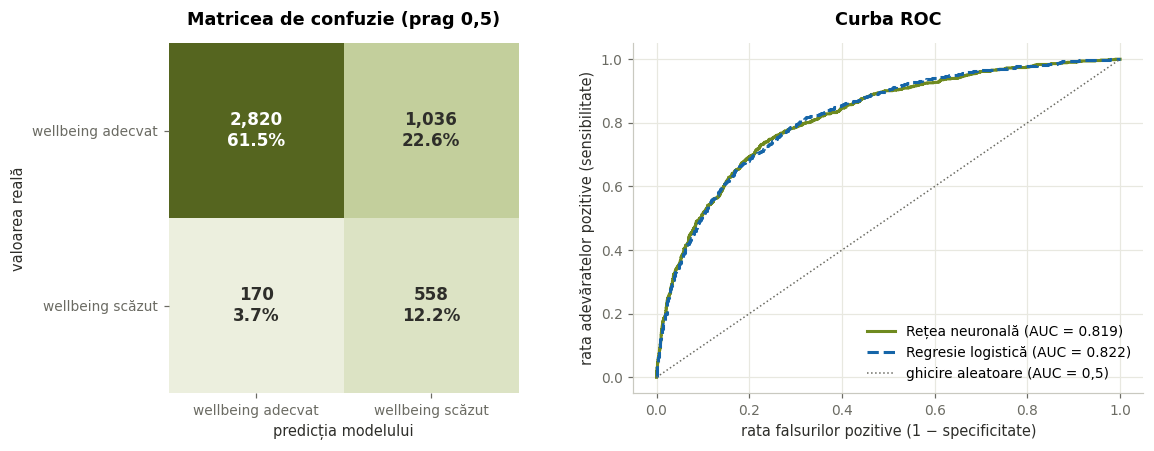

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# --- matricea de confuzie
cm = confusion_matrix(y_test, pred_nn)
im = ax1.imshow(cm, cmap=CMAP_OLIVE, vmin=0)
etich = ["wellbeing adecvat", "wellbeing scăzut"]
ax1.set_xticks([0, 1], etich); ax1.set_yticks([0, 1], etich)
ax1.set_xlabel("predicția modelului"); ax1.set_ylabel("valoarea reală")
ax1.set_title("Matricea de confuzie (prag 0,5)")
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i,j]:,}\n{cm[i,j]/cm.sum()*100:.1f}%", ha="center", va="center",
                 fontsize=11, fontweight="bold",
                 color="white" if cm[i, j] > cm.max()*0.55 else "#2E2E2A")
ax1.grid(False)
for s in ax1.spines.values():
    s.set_visible(False)

# --- curbele ROC
for p, nume, col, ls in [(p_nn, f"Rețea neuronală (AUC = {auc_nn:.3f})", OLIVE, "-"),
                         (p_logit, f"Regresie logistică (AUC = {auc_logit:.3f})", BLUE, "--")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax2.plot(fpr, tpr, color=col, linewidth=2, linestyle=ls, label=nume)
ax2.plot([0, 1], [0, 1], color=GREY, linewidth=1, linestyle=":", label="ghicire aleatoare (AUC = 0,5)")
ax2.set_xlabel("rata falsurilor pozitive (1 − specificitate)")
ax2.set_ylabel("rata adevăratelor pozitive (sensibilitate)")
ax2.set_title("Curba ROC"); ax2.legend(loc="lower right"); ax2.grid(True); ax2.set_axisbelow(True)

plt.tight_layout(); plt.show()

### Interpretare

**1. Rețeaua neuronală și regresia logistică au performanțe aproape identice** (AUC ≈ 0,82).

Acesta nu este un eșec — este un **rezultat valoros**, care merită raportat. Pe date **tabelare** cu variabile Likert, relațiile dintre predictori și țintă
sunt în mare măsură **monotone și aproximativ aditive**. Rețelele neuronale excelează
acolo unde există **interacțiuni complexe și neliniare** sau structură spațială/secvențială
(imagini, text, serii de timp) — nu neapărat pe un chestionar de 27 de întrebări.

> **Lecția practică:** modelul mai complex nu este automat mai bun. Pentru date tabelare,
> regresia logistică (interpretabilă, rapidă) sau modelele de tip *gradient boosting*
> (XGBoost, LightGBM) sunt adesea alegerea mai bună.

**2. Citirea matricei de confuzie** (pe cele 4.584 de observații din test):

| | Semnificație | Consecință practică |
|---|---|---|
| Sus-stânga | **adevărat negativ** — corect identificați ca fiind în regulă | — |
| Sus-dreapta | **fals pozitiv** — alarmă falsă | resurse de intervenție risipite |
| Jos-stânga | **fals negativ** — caz problematic **ratat** | cel mai costisitor într-un context de sănătate ocupațională |
| Jos-dreapta | **adevărat pozitiv** — caz problematic identificat corect | obiectivul nostru |

**3. Atenție la *accuracy*.** *Accuracy* este mai mică decât 84% (cât ar da un model
care prezice mereu clasa 0), dar *balanced accuracy* este mult mai mare. Datorită
`class_weight`, modelul **sacrifică intenționat** acuratețea globală pentru a identifica
mai multe cazuri de wellbeing scăzut. Într-un context de sănătate ocupațională, acesta
este compromisul corect.

## 8.1 Pragul de decizie nu trebuie să fie 0,5

Rețeaua produce o **probabilitate**; pragul care o transformă în decizie 0/1 este o
alegere a noastră, nu o proprietate a modelului. Pragul potrivit depinde de **costul
relativ** al celor două tipuri de eroare.

In [19]:
rand = []
for prag in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    b = (p_nn > prag).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, b, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, b).ravel()
    rand.append({"prag": prag, "precision": pr, "recall": rc, "F1": f1,
                 "accuracy": accuracy_score(y_test, b),
                 "cazuri ratate (FN)": fn, "alarme false (FP)": fp})
tabel_prag = pd.DataFrame(rand).set_index("prag")
tabel_prag.round(3)

,precision,recall,F1,accuracy,cazuri ratate (FN),alarme false (FP)
prag,,,,,,
0.2,0.212,0.951,0.347,0.432,36,2568
0.3,0.255,0.900,0.397,0.567,73,1914
0.4,0.299,0.826,0.439,0.665,127,1407
0.5,0.353,0.771,0.484,0.739,167,1030
0.6,0.418,0.646,0.507,0.801,258,655
0.7,0.506,0.493,0.500,0.843,369,350


### Interpretare

- **Prag mic (0,20–0,30):** **recall** mare — prindem majoritatea cazurilor de wellbeing
  scăzut, dar cu multe alarme false. Potrivit dacă intervenția este ieftină (ex. trimiterea
  unui chestionar de evaluare suplimentar).
- **Prag mare (0,60–0,70):** **precision** mare — aproape toți cei semnalați au efectiv
  probleme, dar ratăm multe cazuri. Potrivit dacă intervenția este costisitoare.
- **`F1`** echilibrează cele două și este un reper rezonabil când nu avem informații
  despre costuri. Pe datele noastre, F1 atinge maximul în jurul pragului **0,6** — nu la
  0,5, pragul implicit.

Priviți coloanele `cazuri ratate (FN)` și `alarme false (FP)`: trecerea de la pragul 0,2
la 0,7 reduce alarmele false de aproape opt ori, dar înzecește numărul de cazuri ratate.

**Nu există un prag „corect" în sens statistic** — este o decizie de politică organizațională,
care depinde de cât costă o intervenție inutilă față de cât costă un caz nedetectat.

---
# 9. Hiperparametrii: ce sunt, ce controlează, cât contează

**Parametri** = ponderile $w$ și bias-urile $b$, pe care rețeaua le **învață** din date.
**Hiperparametri** = setările pe care **noi** le alegem **înainte** de antrenare.

## 9.1 Tabelul de referință

| Hiperparametru | Ce controlează | Valori uzuale (date tabelare) | Dacă e prea MIC | Dacă e prea MARE |
|---|---|---|---|---|
| **Număr de straturi ascunse** | adâncimea: câte niveluri de abstractizare | 1–3 | underfitting — nu captează neliniaritățile | overfitting, antrenare lentă, gradienți instabili |
| **Număr de neuroni / strat** (`units`) | capacitatea fiecărui strat | 16–128, descrescător (32→16) | underfitting | overfitting, mulți parametri |
| **Funcția de activare** (`activation`) | neliniaritatea modelului | **ReLU** ascunse, **sigmoid** output binar | fără activare = model liniar | — |
| **Learning rate** (`learning_rate`) | mărimea pasului de actualizare a ponderilor | 1e-4 … 1e-2 (Adam: **1e-3**) | convergență foarte lentă, blocare în minime locale | oscilații, cost care sare, divergență |
| **Număr de epoci** (`epochs`) | câte treceri complete prin setul de antrenare | 30–200 **+ EarlyStopping** | underfitting | overfitting |
| **Batch size** (`batch_size`) | câte observații per actualizare a ponderilor | **32**, 64, 128, 256 | gradient zgomotos, antrenare lentă | gradient stabil, dar generalizare adesea mai slabă |
| **Dropout** | % de neuroni dezactivați aleator la fiecare pas | 0,1–0,5 | risc de overfitting | underfitting — rețeaua nu reține suficient |
| **Optimizer** | algoritmul de actualizare | **Adam** (implicit), SGD, RMSprop | — | — |
| **Funcția de cost** (`loss`) | ce minimizăm | **binary_crossentropy** (binar), `categorical_crossentropy` (multiclasă), `mse` (regresie) | — | — |
| **`class_weight`** | corectează dezechilibrul de clase | `n/(2·n_clasă)` | clasa minoritară ignorată | prea multe alarme false |

### Reguli practice

1. **Începeți simplu.** Un strat de 32 de neuroni, learning rate 1e-3, batch 32–64.
   Creșteți complexitatea doar dacă `val_loss` arată underfitting.
2. **Learning rate este cel mai important hiperparametru.** Modificați-l primul.
3. **Nu reglați numărul de epoci manual** — folosiți `EarlyStopping`.
4. **Dropout ajută doar dacă există overfitting.** Pe seturi mici cu rețele mici, poate strica.
5. **Nu reglați niciodată hiperparametrii pe setul de test** — doar pe cel de validare.

## 9.2 Experiment: cât contează, pe datele noastre?

Rulăm un **grid search simplificat** — câteva configurații, comparate pe setul de validare.

In [18]:
CONFIGURATII = [
    {"nume": "Referință (32, 16)",       "straturi": (32, 16),      "learning_rate": 1e-3, "dropout": 0.2},
    {"nume": "Fără straturi ascunse",    "straturi": (),            "learning_rate": 1e-3, "dropout": 0.0},
    {"nume": "Rețea mică (8)",           "straturi": (8,),          "learning_rate": 1e-3, "dropout": 0.0},
    {"nume": "Rețea mare (128, 64, 32)", "straturi": (128, 64, 32), "learning_rate": 1e-3, "dropout": 0.2},
    {"nume": "Learning rate mic (1e-5)", "straturi": (32, 16),      "learning_rate": 1e-5, "dropout": 0.2},
    {"nume": "Learning rate mare (0,1)", "straturi": (32, 16),      "learning_rate": 1e-1, "dropout": 0.2},
    {"nume": "Dropout mare (0,6)",       "straturi": (32, 16),      "learning_rate": 1e-3, "dropout": 0.6},
]

rezultate = []
t_total = time.time()
for cfg in CONFIGURATII:
    keras.utils.set_random_seed(42)                       # același punct de plecare
    m = construieste_model(N_FEATURES, straturi=cfg["straturi"],
                           dropout=cfg["dropout"], learning_rate=cfg["learning_rate"])
    t0 = time.time()
    hh = m.fit(X_train_p, y_train, validation_split=0.20, epochs=40, batch_size=64,
               class_weight=class_weight, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                        patience=8, restore_best_weights=True)])
    p_cfg = m.predict(X_test_p, verbose=0).ravel()
    rezultate.append({
        "configurație": cfg["nume"],
        "straturi": str(cfg["straturi"]) if cfg["straturi"] else "—",
        "learning_rate": cfg["learning_rate"],
        "dropout": cfg["dropout"],
        "parametri": m.count_params(),
        "epoci": len(hh.history["loss"]),
        "val_AUC": max(hh.history["val_auc"]),
        "test_AUC": roc_auc_score(y_test, p_cfg) if np.isfinite(p_cfg).all() else np.nan,
        "timp (s)": round(time.time() - t0, 1),
    })
    print(f"  {cfg['nume']:<26s} val_AUC = {rezultate[-1]['val_AUC']:.4f}  "
          f"({rezultate[-1]['epoci']} epoci, {rezultate[-1]['timp (s)']}s)")

tabel = pd.DataFrame(rezultate).sort_values("val_AUC", ascending=False)
print(f"\nTimp total al experimentului: {time.time()-t_total:.0f} secunde")
tabel.round({"val_AUC": 4, "test_AUC": 4})

  Referință (32, 16)         val_AUC = 0.8216  (26 epoci, 4.6s)
  Fără straturi ascunse      val_AUC = 0.8227  (26 epoci, 4.0s)
  Rețea mică (8)             val_AUC = 0.8228  (20 epoci, 3.2s)
  Rețea mare (128, 64, 32)   val_AUC = 0.8310  (16 epoci, 4.0s)
  Learning rate mic (1e-5)   val_AUC = 0.7722  (40 epoci, 6.4s)
  Learning rate mare (0,1)   val_AUC = 0.7869  (11 epoci, 2.6s)
  Dropout mare (0,6)         val_AUC = 0.8241  (35 epoci, 5.8s)

Timp total al experimentului: 31 secunde


,configurație,straturi,learning_rate,dropout,parametri,epoci,val_AUC,test_AUC,timp (s)
3,"Rețea mare (128, 64, 32)","(128, 64, 32)",0.00100,0.2,15233,16,0.8310,0.8218,4.0
6,"Dropout mare (0,6)","(32, 16)",0.00100,0.6,1761,35,0.8241,0.8197,5.8
2,Rețea mică (8),"(8,)",0.00100,0.0,313,20,0.8228,0.8217,3.2
1,Fără straturi ascunse,—,0.00100,0.0,38,26,0.8227,0.8214,4.0
0,"Referință (32, 16)","(32, 16)",0.00100,0.2,1761,26,0.8216,0.8191,4.6
5,"Learning rate mare (0,1)","(32, 16)",0.10000,0.2,1761,11,0.7869,0.7789,2.6
4,Learning rate mic (1e-5),"(32, 16)",0.00001,0.2,1761,40,0.7722,0.7819,6.4


  Rețea mică (8)             val_AUC = 0.8228  (20 epoci, 14.1s)


  Rețea mare (128, 64, 32)   val_AUC = 0.8309  (18 epoci, 18.4s)


  Learning rate mic (1e-5)   val_AUC = 0.7722  (40 epoci, 36.3s)


  Learning rate mare (0,1)   val_AUC = 0.7869  (11 epoci, 10.0s)


  Dropout mare (0,6)         val_AUC = 0.8241  (35 epoci, 30.0s)

Timp total al experimentului: 150 secunde


,configurație,straturi,learning_rate,dropout,parametri,epoci,val_AUC,test_AUC,timp (s)
3,"Rețea mare (128, 64, 32)","(128, 64, 32)",0.00100,0.2,15233,18,0.8309,0.8194,18.4
6,"Dropout mare (0,6)","(32, 16)",0.00100,0.6,1761,35,0.8241,0.8197,30.0
2,Rețea mică (8),"(8,)",0.00100,0.0,313,20,0.8228,0.8217,14.1
1,Fără straturi ascunse,—,0.00100,0.0,38,26,0.8227,0.8214,16.3
0,"Referință (32, 16)","(32, 16)",0.00100,0.2,1761,26,0.8220,0.8198,24.6
5,"Learning rate mare (0,1)","(32, 16)",0.10000,0.2,1761,11,0.7869,0.7789,10.0
4,Learning rate mic (1e-5),"(32, 16)",0.00001,0.2,1761,40,0.7722,0.7819,36.3


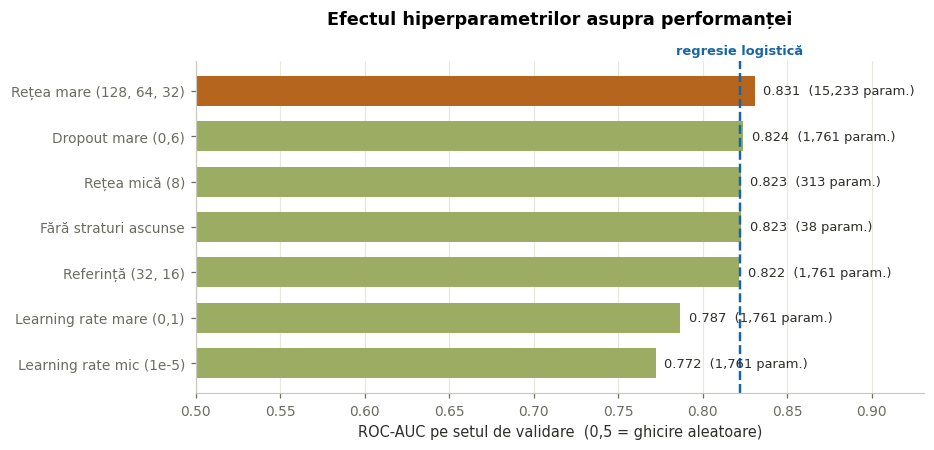

In [19]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
t = tabel.sort_values("val_AUC")
cols = [TERRA if v == t["val_AUC"].max() else OLIVE_RAMP[3] for v in t["val_AUC"]]
ax.barh(range(len(t)), t["val_AUC"], color=cols, height=0.66)
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t["configurație"], fontsize=9)
for i, (v, p) in enumerate(zip(t["val_AUC"], t["parametri"])):
    ax.text(v + 0.005, i, f"{v:.3f}  ({p:,} param.)", va="center", fontsize=8.5, color="#2E2E2A")
ax.axvline(auc_logit, color=BLUE, linewidth=1.6, linestyle="--")
ax.text(auc_logit, 1.01, "regresie logistică", transform=ax.get_xaxis_transform(),
        color=BLUE, fontsize=8.5, ha="center", va="bottom", fontweight="bold")
# axa pornește de la 0,5 = ghicire aleatoare, nu de la 0,7 — altfel diferențele par mai mari decât sunt
ax.set_xlim(0.5, t["val_AUC"].max() + 0.10)
ax.set_xlabel("ROC-AUC pe setul de validare  (0,5 = ghicire aleatoare)")
ax.set_title("Efectul hiperparametrilor asupra performanței", pad=24)
ax.grid(axis="x"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### Interpretare

**1. Learning rate este singurul hiperparametru care contează mult aici.**
Ambele valori extreme pierd clar: cu `lr = 1e-5` pașii sunt atât de mici încât rețeaua
nu are timp să învețe în 40 de epoci (**underfitting** — rulează toate cele 40 de epoci
fără să se oprească); cu `lr = 1e-1` pașii sunt atât de mari încât optimizarea devine
instabilă și `EarlyStopping` o oprește după ~10 epoci. Este exact comportamentul descris
la curs: *„valori mici duc la o învățare mai lentă, dar stabilă; valori mari pot împiedica
convergența"*.

**2. Dimensiunea rețelei aproape nu contează — comparați coloanele `parametri` și `test_AUC`.**
De la **38 de parametri** (fără straturi ascunse) la **15.233** (128–64–32), AUC-ul pe
setul de test rămâne în jur de **0,82**. Un model de 400 de ori mai mare nu aduce nimic.

**3. Cea mai importantă lecție a tabelului: comparați `val_AUC` cu `test_AUC`.**
Rețeaua mare are **cel mai bun `val_AUC`** — dar **nu cel mai bun `test_AUC`**. Diferența
de ~0,009 pe validare este **zgomot de selecție**, nu performanță reală. Aceasta este
întreaga justificare a separării în trei seturi: dacă am alege arhitectura pe baza setului
de test, am raporta o performanță optimistă și falsă.

> **Regula:** hiperparametrii se aleg pe **validare**; setul de test se folosește o
> singură dată, la final, exclusiv pentru raportare.

**4. Rețeaua fără straturi ascunse** este, matematic, o regresie logistică — și obține
practic același AUC. Comparația ei cu celelalte configurații măsoară direct **cât aduce
neliniaritatea** pe aceste date: aproape nimic.

**5. Dropout 0,6 nu strică performanța, dar încetinește antrenarea** (35 de epoci în loc
de 26). Pe un model deja mic și pe o problemă aproape liniară, nu există overfitting de
combătut — deci regularizarea nu are ce să corecteze. Confirmă regula practică:
**dropout ajută doar dacă există overfitting.**

### În practică: metode automate de tuning

Comparația manuală de mai sus devine imposibilă când avem mulți hiperparametri. Metodele
din curs, în ordinea eficienței:

| Metodă | Cum funcționează | Când se folosește |
|---|---|---|
| **GridSearchCV** | testează **toate** combinațiile | puțini hiperparametri, puține valori |
| **RandomizedSearchCV** | alege aleator combinații din intervale date | mulți hiperparametri sau intervale largi |
| **Optuna** (optimizare bayesiană) | **învață din evaluările anterioare** și decide ce combinație merită testată | spații mari de căutare, antrenare costisitoare |

Pentru Keras, `GridSearchCV` necesită pachetul `scikeras`; `Optuna` se integrează direct
și este alegerea recomandată pentru proiecte reale.

---
# 10. Ce a învățat rețeaua? (permutation importance)

O rețea neuronală este o **cutie neagră**: nu are coeficienți interpretabili ca regresia
logistică. Putem însă afla **cât se bazează** pe fiecare variabilă prin
**permutation importance**:

> Amestecăm aleator valorile unei singure variabile (distrugându-i legătura cu ținta),
> recalculăm AUC și măsurăm **cât scade performanța**. O scădere mare = variabilă importantă.

In [22]:
def permutation_importance_nn(model, preproc, X_df, y_true, n_repeats=3, seed=42):
    rng = np.random.default_rng(seed)
    auc_baza = roc_auc_score(y_true, model.predict(preproc.transform(X_df), verbose=0).ravel())
    out = []
    for col in X_df.columns:
        scaderi = []
        for _ in range(n_repeats):
            Xp = X_df.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            auc_p = roc_auc_score(y_true, model.predict(preproc.transform(Xp), verbose=0).ravel())
            scaderi.append(auc_baza - auc_p)
        out.append({"variabila": col, "scadere_AUC": np.mean(scaderi), "ab_std": np.std(scaderi)})
    return auc_baza, pd.DataFrame(out).sort_values("scadere_AUC", ascending=False)


t0 = time.time()
auc_baza, imp = permutation_importance_nn(model, preproc, X_test, y_test, n_repeats=3)
print(f"Calculat în {time.time()-t0:.0f} secunde | AUC de referință: {auc_baza:.4f}\n")
imp = imp.merge(dic[["variabila", "label"]], on="variabila", how="left")
imp.head(12).round(4)[["variabila", "label", "scadere_AUC", "ab_std"]]

Calculat în 21 secunde | AUC de referință: 0.8198



,variabila,label,scadere_AUC,ab_std
0,selfrated_health,Starea de sănătate autoevaluată,0.0597,0.0009
1,recognition,Recunoașterea primită,0.0277,0.0015
2,exhaust_emot,Epuizarea emoțională,0.0154,0.0028
3,stress,Frecvența stresului,0.0127,0.0013
4,work_life_balance,Echilibrul muncă–viață,0.0091,0.0014
5,enough_time,Timpul suficient pentru sarcini,0.0072,0.0033
6,wlb_worry,Griji legate de muncă,0.0049,0.0008
7,make_ends_meet,Dificultatea financiară a gospodăriei,0.0045,0.0017
8,seniority,Vechimea în organizație,0.0030,0.0010
9,highspeed,Munca în ritm alert,0.0024,0.0006


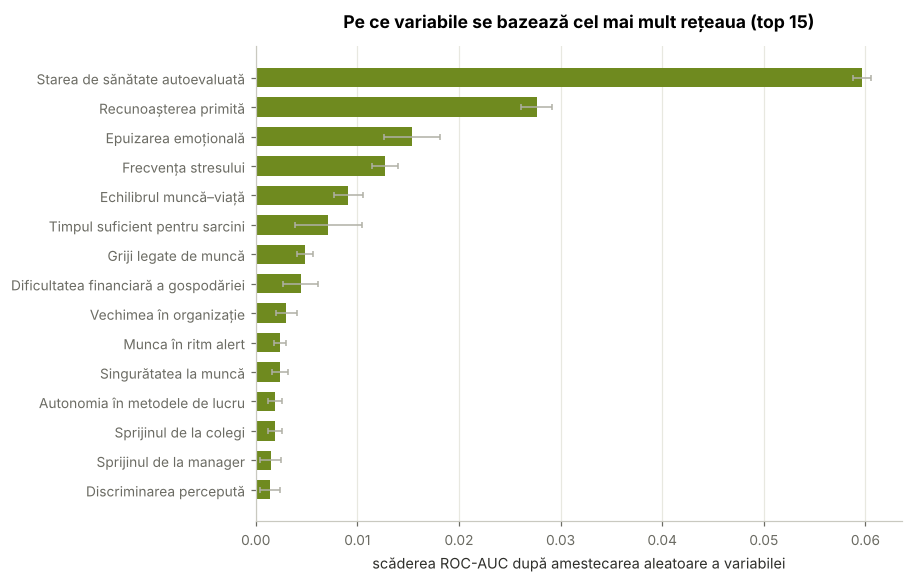

In [23]:
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.barh(range(len(top)), top["scadere_AUC"], xerr=top["ab_std"],
        color=OLIVE, height=0.66, error_kw={"ecolor": "#B0B0A6", "elinewidth": 1, "capsize": 2})
ax.set_yticks(range(len(top))); ax.set_yticklabels(top["label"], fontsize=9)
ax.set_xlabel("scăderea ROC-AUC după amestecarea aleatoare a variabilei")
ax.set_title("Pe ce variabile se bazează cel mai mult rețeaua (top 15)")
ax.grid(axis="x"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### Interpretare

Ierarhia este foarte **concentrată** — doar câteva variabile contează real:

- **Sănătatea autoevaluată** domină detașat: amestecarea ei singură scade AUC-ul de peste
  două ori mai mult decât oricare altă variabilă. Sănătatea fizică percepută și bunăstarea
  psihologică sunt strâns legate, ceea ce este de așteptat.
- **Recunoașterea primită** la locul de muncă este, surprinzător, pe locul al doilea —
  înaintea stresului și a epuizării emoționale. Sentimentul că munca ta este apreciată
  cântărește mai mult decât volumul de muncă în sine.
- Urmează **epuizarea emoțională**, **frecvența stresului** și **echilibrul muncă–viață** —
  nucleul clasic al cerințelor muncii din modelul *Job Demands–Resources*.
- **Autonomia** are importanță mică în acest model, deși în literatură este o resursă
  centrală — vezi avertismentul 2 mai jos.
- Variabilele **socio-demografice** (vârstă, sex, sector, educație, venit) **nu apar deloc
  în primele 12**. Wellbeing-ul este explicat de **ce trăiește** persoana la muncă, nu de
  **cine este** — un rezultat cu implicații directe de politică organizațională.

Observați și **cât de mici sunt scăderile în valoare absolută**: 0,06 pentru prima
variabilă, sub 0,03 pentru toate celelalte. Niciun predictor nu este indispensabil —
modelul se bazează pe acumularea multor semnale slabe, nu pe câteva puternice.

### Trei avertismente importante

1. **Importanța ≠ cauzalitate.** EWCS este un sondaj **transversal** (o singură măsurare
   în timp). Nu putem spune dacă epuizarea emoțională *cauzează* wellbeing scăzut sau
   invers — probabil ambele, într-un cerc vicios.
2. **Variabilele corelate își „împart" importanța.** `stress` și `exhaust_emot` măsoară
   lucruri apropiate; amestecarea uneia poate părea inofensivă pentru că informația rămâne
   disponibilă în cealaltă.
3. **Măsurare prin auto-raportare.** Atât predictorii, cât și ținta provin din același
   chestionar completat de aceeași persoană — ceea ce poate umfla artificial asocierile
   (*common method bias*).

---
# 11. Predicții pentru observații noi

## Pasul 6 din curs: utilizarea modelului antrenat

Construim trei profile ipotetice de salariat, pornind de la **valoarea mediană** a
fiecărei variabile și modificând doar condițiile de muncă.

In [24]:
# profil de bază: mediana pentru variabilele numerice, modul pentru cele categoriale
baza = {c: X_train[c].median() for c in NUMERICE}
baza.update({c: X_train[c].mode()[0] for c in CATEGORIALE})

profile = {
    "A — condiții favorabile": {"stress": 2, "exhaust_emot": 1, "wlb_worry": 2, "lonely": 1,
                                "support_manager": 5, "support_colleagues": 5, "fair_treatment": 5,
                                "recognition": 5, "enough_time": 5, "autonomy_methods": 4,
                                "work_life_balance": 4, "make_ends_meet": 2, "selfrated_health": 5,
                                "losejob": 1, "discrimination": 0},
    "B — profil median":       {},
    "C — condiții nefavorabile": {"stress": 5, "exhaust_emot": 5, "wlb_worry": 5, "lonely": 4,
                                "support_manager": 1, "support_colleagues": 2, "fair_treatment": 2,
                                "recognition": 1, "enough_time": 2, "autonomy_methods": 1,
                                "work_life_balance": 1, "make_ends_meet": 6, "selfrated_health": 2,
                                "losejob": 4, "discrimination": 1},
}

X_nou = pd.DataFrame([{**baza, **mod} for mod in profile.values()],
                     index=list(profile.keys()))[NUMERICE + CATEGORIALE]

prob = model.predict(preproc.transform(X_nou), verbose=0).ravel()

rez = pd.DataFrame({
    "probabilitate wellbeing scăzut": prob.round(3),
    "clasificare (prag 0,5)": np.where(prob > 0.5, "wellbeing SCĂZUT", "wellbeing adecvat"),
}, index=X_nou.index)
rez

,probabilitate wellbeing scăzut,"clasificare (prag 0,5)"
A — condiții favorabile,0.043,wellbeing adecvat
B — profil median,0.394,wellbeing adecvat
C — condiții nefavorabile,0.993,wellbeing SCĂZUT


### Interpretare

- Modelul separă **net** cele trei profile — de la ~4% la peste 99% — deși **vârsta,
  venitul, sectorul, educația și toate caracteristicile socio-demografice sunt identice**.
  Singura diferență sunt condițiile de muncă.

- **Atenție: aceste valori nu sunt probabilități calibrate.** Profilul median primește
  ~0,39, deși rata reală în eșantion este de 16%. Motivul este `class_weight`: am
  instruit rețeaua să considere o eroare pe clasa minoritară de 5,3 ori mai costisitoare,
  deci ieșirile sunt **sistematic deplasate în sus**. Ele sunt **scoruri de decizie**
  utile pentru ordonarea cazurilor, nu estimări ale riscului absolut.

  > Dacă aveți nevoie de probabilități interpretabile ca atare (de exemplu „acest salariat
  > are 23% risc"), antrenați **fără** `class_weight` sau aplicați o **calibrare**
  > ulterioară — *Platt scaling* / `CalibratedClassifierCV` din scikit-learn.

- Reținem și că aceasta rămâne o **asociere statistică** la nivel de grup, nu o predicție
  individuală de încredere. Pentru o persoană reală, incertitudinea este mult mai mare
  decât sugerează o singură cifră.

---
# 12. Concluzii

### Ce am construit

Un **MLP feedforward** în Keras care prezice, pe baza a 27 de variabile despre condițiile
de muncă, dacă un salariat european are bunăstare psihologică scăzută (WHO-5 < 50):
**ROC-AUC ≈ 0,82** pe 4.584 de observații de test nevăzute.

### Ce am învățat metodologic

1. **Scalarea variabilelor nu este opțională** pentru rețele neuronale — fără ea,
   coborârea pe gradient nu funcționează corect.
2. **Un baseline este obligatoriu.** Regresia logistică a obținut practic același AUC,
   ceea ce este o informație la fel de valoroasă ca performanța rețelei.
3. **Curbele de învățare** sunt instrumentul principal de diagnostic: arată simultan
   dacă modelul învață și când începe să memoreze.
4. **Learning rate este hiperparametrul cel mai important**; dimensiunea rețelei
   contează mult mai puțin decât ne-am aștepta.
5. **Pe clase dezechilibrate, *accuracy* este înșelătoare.** ROC-AUC, balanced accuracy
   și matricea de confuzie spun povestea reală.
6. **Pragul de decizie este o alegere de politică**, nu un rezultat statistic.
7. **Hiperparametrii se aleg pe setul de validare, niciodată pe cel de test** — altfel
   raportăm o performanță optimistă și falsă (secțiunea 9, punctul 3).
8. **Ieșirile unui model antrenat cu `class_weight` nu sunt probabilități calibrate**, ci
   scoruri de decizie.

### Limitele acestui exercițiu

- Date **transversale** → **asocieri, nu cauzalitate**.
- Am ignorat **ponderile de sondaj** (`calweight`). Pentru estimări reprezentative la
  nivel european, ele trebuie folosite — vezi exercițiul 4.
- Am eliminat 21,9% din salariați prin **ștergerea listwise** a non-răspunsurilor. Ar fi
  mai corect să **imputăm** valorile lipsă.
- Atât predictorii, cât și ținta provin din **auto-raportare**, în același chestionar.

---

# Exerciții

**1. Arhitectura.** Modificați `straturi=(64, 32, 16)` și `dropout=0.3`. Se îmbunătățește
`val_auc`? Priviți curbele de învățare înainte de a răspunde.

**2. Batch size.** Rulați modelul de referință cu `batch_size` 32, 128 și 512. Cum se
schimbă timpul de antrenare și AUC? De ce?

**3. Efectul țării.** Adăugați `country` la lista `CATEGORIALE` (devin 34 de coloane
one-hot suplimentare). Crește performanța? Ce vă spune asta despre diferențele dintre
țările europene?

**4. Ponderile de sondaj.** Transmiteți `sample_weight=df.loc[X_train.index, "calweight"]`
către `model.fit()`. Cum se modifică rezultatele?

**5. Fără `class_weight`.** Antrenați modelul fără `class_weight`. Comparați *accuracy*
și *balanced accuracy*. Ce „învață" modelul să facă?

**6. Regresie în loc de clasificare.** Prediceți direct scorul continuu `wellbeing`
(0–100). Schimbați: activarea stratului de ieșire în `"linear"`, `loss="mse"`,
metricile în `["mae"]`. Interpretați eroarea medie absolută în puncte WHO-5.

**7. Comparație cu gradient boosting.** Antrenați un
`HistGradientBoostingClassifier` din `sklearn.ensemble` pe aceleași date. Depășește
rețeaua neuronală? Comentați rezultatul în lumina secțiunii 8.